# 06 - Choisir un modele pre-entraine et la bonne strategie de transfert

Un reseau entraine sur ImageNet (1,2 million d'images, 1 000 classes) sait deja voir des bords,
des textures, des formes. Le transfer learning reutilise ce savoir : on remplace la derniere
couche par une couche a nos classes, puis on decide QUOI entrainer. Ce notebook :

1. compare les modeles disponibles (taille, vitesse, precision ImageNet) ;
2. montre l'anatomie d'un reseau (tete, premiere convolution, blocs) et les mecanismes : gel,
   degel, BatchNorm, taux par groupe de couches, entree a 1 canal ;
3. compare les cinq strategies (features, head, partial, full, progressive) sur NEU-CLS.

- Donnees : NEU-CLS (`python tools/get_data/get_neu_cls.py`).
- Poids : seuls ceux de resnet18 sont dans le cache de cet environnement ; les autres modeles
  sont mesures sans poids (taille, vitesse) et se telechargent au premier usage
  (`tools/fetch_weights.py` pour un poste sans Internet).
- Duree en mode QUICK sur un CPU 2 coeurs : 4 a 6 minutes.

**Dans le fil** : ce notebook approfondit l'etape 8 (Modele : choisir un reseau pre-entraine, geler,
degeler) et, pour les taux par groupe de couches, l'etape 9 (Perte et optimiseur). La comparaison
des cinq strategies deroule en court les etapes 8 a 11.
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 1. Reglages (etape 1)

In [1]:
import copy  # copy : copie profonde d'objets (sauvegarde du meilleur modele)
import math  # math : cosinus et pi (planning du taux en cosinus)
import time  # time : chronometre
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture et redimensionnement des images
import matplotlib.pyplot as plt  # matplotlib : graphiques
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) faciles a afficher
import torch  # PyTorch : tenseurs (tableaux de nombres sur CPU ou GPU) et reseaux de neurones
import torch.nn as nn  # nn : les briques des reseaux (couches, fonctions de perte)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire (strategie features)
from sklearn.metrics import f1_score  # F1 : moyenne harmonique de la precision et du rappel
from sklearn.model_selection import train_test_split  # decoupe un jeu en deux parties au hasard (ici stratifie)
from sklearn.preprocessing import StandardScaler  # met chaque variable a moyenne 0 et ecart-type 1
from torch.utils.data import DataLoader, Dataset  # Dataset : jeu d'exemples ; DataLoader : le sert par lots (paquets d'images)
from torchvision import models  # models : reseaux pre-entraines de torchvision
from torchvision.transforms import v2  # v2 : transformations d'images de torchvision (augmentation)

from vtb import viz  # viz : fonctions d'affichage de la toolbox

QUICK = True  # True : petit train (50 images par classe), 96 px, peu d'epoques ; False : reglages de la recette
DATA_DIR = Path("data/raw/neu_cls_flat")  # NEU-CLS : un sous-dossier par classe de defaut
EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions reconnues comme images
IMAGE_SIZE = 96 if QUICK else 128  # cote des images en entree du reseau (pixels)
TRAIN_PER_CLASS = 50 if QUICK else None  # images d'entrainement par classe en mode rapide ; None : tout le train (1 260 images)
LATENCY_RUNS = 5 if QUICK else 20  # nombre d'inferences chronometrees par modele
# Reglages des cinq strategies (QUICK=False : ceux des YAML de la recette, resnet18_<strategie>.yaml)
STRATEGIES = {  # reglages de chaque strategie : epoques, taux d'apprentissage lr, planning du taux...
    # head : seule la tete apprend ; plateau = taux divise quand la validation stagne
    "head": {"epochs": 4 if QUICK else 8, "lr": 1e-3, "scheduler": "plateau"},
    # partial : tete + dernier bloc ; le backbone (le reseau sous la tete) apprend 10 fois moins vite
    "partial": {"epochs": 4 if QUICK else 10, "lr": 1e-3, "scheduler": "plateau", "unfreeze_last": 1, "backbone_lr_factor": 0.1},
    # full : tout apprend, taux faible ; cosine = taux qui decroit en cosinus apres 1 epoque de montee (warmup)
    "full": {"epochs": 4 if QUICK else 8, "lr": 3e-4, "scheduler": "cosine", "warmup_epochs": 1, "backbone_lr_factor": 0.1},
    "progressive": {  # progressive : un bloc de plus degele a intervalles reguliers :
        "epochs": 5 if QUICK else 10,  # nombre d'epoques (une epoque = un passage complet sur le train)
        "lr": 1e-3,  # taux d'apprentissage de la tete (taille des pas de correction des poids)
        "scheduler": "none",  # pas de planning du taux
        "progressive_every": 1 if QUICK else 2,  # un bloc de plus degele toutes les N epoques
        "backbone_lr_factor": 0.1,  # taux du backbone = lr x 0,1
        "layer_decay": 0.5,  # chaque bloc plus profond (plus pres de l'entree) : taux encore divise par 2
    },
}
BATCH_SIZE, PATIENCE, SEED = 32, 4, 42  # 32 images par lot ; arret apres 4 epoques sans progres ; graine du hasard
# calcule sur la carte graphique (GPU, "cuda") si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/06_modeles_transfert")  # dossier des fichiers ecrits par ce notebook
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier et ses parents ; pas d'erreur s'il existe deja
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures a 80 points par pouce, en jpeg (notebook plus leger)
torch.manual_seed(SEED)  # graine de PyTorch : memes poids aleatoires et memes tirages a chaque execution
np.random.seed(SEED)  # graine de numpy

## 2. Le catalogue : taille, vitesse, precision ImageNet (etape 8 : le catalogue des modeles)

Trois questions pour choisir : combien de calcul par image (latence sur la machine de
production), combien de memoire (parametres), quelle qualite des representations (la precision
ImageNet en donne un ordre d'idee, pas une garantie sur des images d'acier). Les precisions
viennent des metadonnees de torchvision, les latences sont mesurees ici (CPU, lot de 1, 224 px,
poids aleatoires : la vitesse ne depend pas des valeurs des poids).

In [2]:
TORCHVISION = {  # constructeur torchvision -> nom de la classe de ses poids pre-entraines :
    "resnet18": "ResNet18_Weights",  # ResNet a 18 couches : rapide et robuste
    "resnet34": "ResNet34_Weights",  # ResNet a 34 couches
    "resnet50": "ResNet50_Weights",  # ResNet a 50 couches (blocs plus larges)
    "efficientnet_b0": "EfficientNet_B0_Weights",  # EfficientNet B0 : bon rapport precision / calcul
    "mobilenet_v3_small": "MobileNet_V3_Small_Weights",  # MobileNet V3 petit : pour l'embarque
    "mobilenet_v3_large": "MobileNet_V3_Large_Weights",  # MobileNet V3 grand
    "convnext_tiny": "ConvNeXt_Tiny_Weights",  # ConvNeXt tiny : moderne, plus lourd
    "regnet_y_800mf": "RegNet_Y_800MF_Weights",  # RegNet Y 800 MFLOPs
}
CACHE = Path(torch.hub.get_dir()) / "checkpoints"  # dossier ou PyTorch range les poids telecharges


@torch.inference_mode()  # decorateur : aucun suivi des gradients dans la fonction (calcul plus rapide)
def latency_ms(net, size=224, runs=LATENCY_RUNS):  # temps moyen d'une inference (lot de 1 image) en millisecondes
    net.eval()  # mode evaluation (BatchNorm et Dropout figes)
    x = torch.randn(1, 3, size, size)  # image aleatoire : lot de 1, 3 canaux, size x size pixels
    for _ in range(2):  # 2 passages d'echauffement, non chronometres...
        net(x)  # ...le premier appel paie des initialisations
    start = time.perf_counter()  # depart du chronometre
    for _ in range(runs):  # runs passages chronometres
        net(x)  # une inference
    return 1000 * (time.perf_counter() - start) / runs  # duree moyenne par passage, en millisecondes


rows = []  # une ligne par modele
for name, enum in TORCHVISION.items():  # pour chaque modele torchvision
    weights = getattr(models, enum).DEFAULT  # description des poids par defaut (url, precision ImageNet...), sans les telecharger
    net = getattr(models, name)(weights=None)  # construit le reseau avec des poids aleatoires (la vitesse n'en depend pas)
    rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "modele": name,  # nom du modele
            "source": "torchvision",  # bibliotheque d'origine
            # nombre de parametres en millions (numel = nombre de valeurs d'un tenseur)
            "parametres (M)": round(sum(p.numel() for p in net.parameters()) / 1e6, 1),
            "top1 ImageNet": weights.meta["_metrics"]["ImageNet-1K"]["acc@1"],  # precision top-1 ImageNet donnee par torchvision (%)
            "latence CPU (ms)": round(latency_ms(net), 1),  # latence mesuree ici
            "poids en cache": (CACHE / Path(weights.url).name).exists(),  # poids deja telecharges ?
        }
    )
try:  # timm est optionnel : on essaie de l'importer...
    import timm  # timm : grande collection de modeles de vision

    for name in ["resnet18", "efficientnet_b0", "convnext_nano", "mobilenetv3_large_100", "vit_tiny_patch16_224"]:  # quelques modeles timm
        try:  # le nom peut manquer selon la version...
            net = timm.create_model(name, pretrained=False)  # modele sans poids pre-entraines (mesure de taille et de vitesse)
        # ...dans ce cas on passe au suivant ("noqa" dit a ruff d'accepter ce except large)
        except Exception:  # noqa: BLE001 - nom absent de cette version de timm
            continue  # modele suivant
        rows.append(  # ligne du tableau :
            {  # dictionnaire de la ligne
                "modele": f"timm:{name}",  # nom du modele
                "source": "timm",  # bibliotheque d'origine
                "parametres (M)": round(sum(p.numel() for p in net.parameters()) / 1e6, 1),  # nombre de parametres en millions
                "top1 ImageNet": np.nan,  # precision ImageNet non fournie ici (NaN = valeur manquante)
                "latence CPU (ms)": round(latency_ms(net), 1),  # latence mesuree ici
                "poids en cache": False,  # non verifie pour timm
            }
        )
except ImportError:  # timm n'est pas installe...
    print("timm absent : pip install timm")  # ...on le dit et on continue
zoo = pd.DataFrame(rows)  # tableau du catalogue
display(zoo)  # affiche le tableau

,modele,source,parametres (M),top1 ImageNet,latence CPU (ms),poids en cache
0,resnet18,torchvision,11.7,69.758,21.5,True
1,resnet34,torchvision,21.8,73.314,37.4,False
2,resnet50,torchvision,25.6,80.858,50.0,False
3,efficientnet_b0,torchvision,5.3,77.692,19.1,False
4,mobilenet_v3_small,torchvision,2.5,67.668,5.7,False
5,mobilenet_v3_large,torchvision,5.5,75.274,15.8,False
6,convnext_tiny,torchvision,28.6,82.520,55.1,False
7,regnet_y_800mf,torchvision,6.4,78.828,26.6,False
8,timm:resnet18,timm,11.7,NaN,44.2,False
9,timm:efficientnet_b0,timm,5.3,NaN,26.3,False


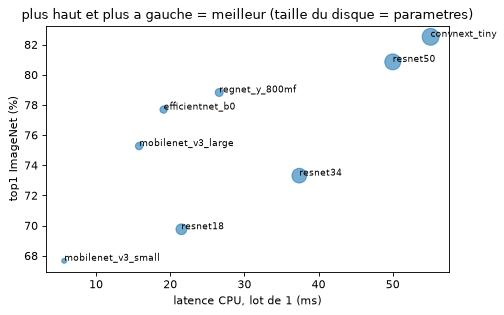

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))  # figure de 6,5 x 4 pouces
known = zoo.dropna(subset=["top1 ImageNet"])  # seulement les modeles dont on connait la precision ImageNet
# un disque par modele : latence en x, precision en y, surface ~ nombre de parametres
ax.scatter(known["latence CPU (ms)"], known["top1 ImageNet"], s=known["parametres (M)"] * 8, alpha=0.6)
for _, row in known.iterrows():  # pour chaque modele...
    ax.annotate(row["modele"], (row["latence CPU (ms)"], row["top1 ImageNet"]), fontsize=8)  # ...ecrit son nom a cote de son point
ax.set_xlabel("latence CPU, lot de 1 (ms)")  # titre de l'axe x
ax.set_ylabel("top1 ImageNet (%)")  # titre de l'axe y
ax.set_title("plus haut et plus a gauche = meilleur (taille du disque = parametres)")  # titre du graphique
plt.show()  # affiche la figure

Regle de depart : **resnet18** (rapide, robuste, 11,7 M de parametres) ; **efficientnet_b0** ou
**regnet_y_800mf** pour mieux a cout egal ; **mobilenet_v3** pour un PC industriel ou de
l'embarque ; **convnext_tiny** ou un modele timm quand la precision prime et que le GPU suit.
On compare toujours sur SES images (le rang ImageNet ne se transpose pas toujours).

## 3. Anatomie d'un reseau pre-entraine (etape 8)

Trois noms suffisent pour tout faire : la **tete** (derniere couche lineaire, remplacee), la
**premiere convolution** (adaptee si l'image n'a pas 3 canaux), les **blocs** du backbone dans
l'ordre (pour degeler du haut vers le bas). Ils changent d'une famille a l'autre :

| famille | tete | premiere convolution | blocs |
|---|---|---|---|
| resnet | `fc` | `conv1` | `layer1` a `layer4` |
| efficientnet | `classifier.1` | `features.0.0` | `features.1` a `features.8` |
| mobilenet_v3 | `classifier.3` | `features.0.0` | `features.1` a `features.12` / `16` |
| convnext | `classifier.2` | `features.0.0` | `features.1` a `features.7` |
| regnet | `fc` | `stem.0` | `trunk_output.block1` a `block4` |

In [4]:
net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # resnet18 avec ses poids ImageNet
anatomy = pd.DataFrame(  # tableau des modules de premier niveau :
    # pour chaque sous-module direct (nom, module) : son type et son nombre de parametres
    [{"module": n, "type": type(m).__name__, "parametres": sum(p.numel() for p in m.parameters())} for n, m in net.named_children()]
)
# part de chaque module dans le total des parametres
anatomy["part (%)"] = (100 * anatomy["parametres"] / anatomy["parametres"].sum()).round(1)
print(anatomy.to_string(index=False))  # affiche le tableau sans numeros de ligne
print("\nla tete a remplacer :", net.fc)  # la tete : couche lineaire 512 -> 1000 classes ImageNet

 module              type  parametres  part (%)
  conv1            Conv2d        9408       0.1
    bn1       BatchNorm2d         128       0.0
   relu              ReLU           0       0.0
maxpool         MaxPool2d           0       0.0
 layer1        Sequential      147968       1.3
 layer2        Sequential      525568       4.5
 layer3        Sequential     2099712      18.0
 layer4        Sequential     8393728      71.8
avgpool AdaptiveAvgPool2d           0       0.0
     fc            Linear      513000       4.4

la tete a remplacer : Linear(in_features=512, out_features=1000, bias=True)


`layer4` porte plus de 70 % des parametres : le degeler (strategie partial) fait apprendre beaucoup de
poids, d'ou un taux 10 fois plus faible que la tete.

## 4. Geler, degeler, et le piege des BatchNorm (etape 8)

Geler = `requires_grad = False` : le gradient ne calcule plus ces poids et l'optimiseur ne les
recoit pas. MAIS une BatchNorm en mode `train()` met a jour ses statistiques glissantes
(moyenne, variance) a chaque passage, gelee ou non : les statistiques ImageNet derivent vers
celles de nos images. Sur un domaine loin d'ImageNet, on remet en `eval()` les BatchNorm des
blocs geles apres chaque `model.train()`.

In [5]:
BLOCKS = ["layer1", "layer2", "layer3", "layer4"]  # les 4 blocs du backbone resnet, de l'entree vers la sortie


def build_resnet18(num_classes, pretrained=True):  # resnet18 avec une tete neuve a num_classes sorties ; renvoie le modele
    # poids ImageNet si pretrained, sinon poids aleatoires
    net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
    net.fc = nn.Linear(net.fc.in_features, num_classes)  # remplace la tete : meme entree (512 valeurs), une sortie par classe
    return net  # renvoie le modele


# regle quels parametres apprennent (requires_grad) selon la strategie ; ne renvoie rien
def apply_strategy(net, strategy, unfreeze_last=1, unfrozen_blocks=0):
    """requires_grad selon la strategie ; unfrozen_blocks : nombre de blocs degeles (progressive)."""
    for p in net.parameters():  # pour chaque parametre du reseau...
        p.requires_grad = strategy == "full"  # ...appris seulement en strategie full (gele sinon)
    if strategy in ("full", "features"):  # full : tout apprend ; features : rien n'apprend...
        return  # ...c'est deja regle
    for p in net.fc.parameters():  # pour les parametres de la tete...
        p.requires_grad = True  # ...ils apprennent toujours
    n = {"head": 0, "partial": unfreeze_last, "progressive": unfrozen_blocks}[strategy]  # nombre de blocs a degeler selon la strategie
    for block in BLOCKS[len(BLOCKS) - n :]:  # les n derniers blocs (les plus proches de la sortie) ; aucun si n = 0
        for p in getattr(net, block).parameters():  # pour chaque parametre du bloc (getattr : attribut designe par son nom)
            p.requires_grad = True  # degele


def freeze_frozen_batchnorm(net):  # remet en mode eval les BatchNorm gelees : leurs statistiques ImageNet ne bougent plus
    for module in net.modules():  # pour chaque couche du reseau (a tous les niveaux)
        # BatchNorm (normalisation par lot) dont aucun parametre n'apprend...
        if isinstance(module, nn.BatchNorm2d) and not any(p.requires_grad for p in module.parameters()):
            module.eval()  # ...mode eval : statistiques glissantes figees


def count_trainable(net):  # nombre de valeurs qui apprennent (parametres avec requires_grad)
    return sum(p.numel() for p in net.parameters() if p.requires_grad)  # somme des tailles des parametres entraines


demo = build_resnet18(6)  # resnet18 a 6 classes pour la demonstration
apply_strategy(demo, "partial")  # gele tout sauf la tete et layer4
# parametres entraines / total ({:,} ajoute des separateurs de milliers)
print(f"partial : {count_trainable(demo):,} parametres entraines sur {sum(p.numel() for p in demo.parameters()):,}")
before = demo.layer1[0].bn1.running_mean.clone()  # copie de la moyenne glissante d'une BatchNorm de layer1 (bloc gele)
demo.train()  # mode entrainement : toutes les BatchNorm mettent a jour leurs statistiques
demo(torch.rand(8, 3, 96, 96))  # un passage sur un lot de 8 images aleatoires
# ecart maximal de la moyenne glissante : non nul, bien que layer1 soit gele
print("layer1 gele, mode train   : moyenne glissante modifiee de", f"{(demo.layer1[0].bn1.running_mean - before).abs().max():.3f}")
demo.layer1[0].bn1.running_mean.copy_(before)  # remet la valeur d'origine
demo.train()  # mode entrainement...
freeze_frozen_batchnorm(demo)  # ...puis fige les BatchNorm des blocs geles
demo(torch.rand(8, 3, 96, 96))  # meme passage
# ecart : 0 cette fois
print("apres freeze_frozen_batchnorm : modifiee de", f"{(demo.layer1[0].bn1.running_mean - before).abs().max():.3f}")

partial : 8,396,806 parametres entraines sur 11,179,590


layer1 gele, mode train   : moyenne glissante modifiee de 0.102
apres freeze_frozen_batchnorm : modifiee de 0.000


## 5. Un taux d'apprentissage par groupe de couches (etape 9)

La tete neuve apprend au taux `lr` ; chaque bloc degele a `lr x backbone_lr_factor x
layer_decay^profondeur` (profondeur 0 = le bloc le plus proche de la sortie). Avec
`layer_decay < 1`, plus un bloc est proche de l'entree (bords, textures generiques), moins il
bouge. L'optimiseur recoit ces groupes ; il ne connait QUE les parametres qu'on lui donne (d'ou
un optimiseur recree a chaque degel en strategie progressive).

In [6]:
# groupes de parametres avec chacun son taux (tete, puis blocs du plus proche au plus lointain) ; renvoie une liste
def param_groups(net, lr, backbone_lr_factor=0.1, layer_decay=1.0):
    head = [p for p in net.fc.parameters() if p.requires_grad]  # parametres de la tete qui apprennent
    groups = [{"params": head, "lr": lr, "name": "fc"}]  # 1er groupe : la tete, au taux lr
    seen = {id(p) for p in head}  # identifiants (id) des parametres deja ranges
    for depth, block in enumerate(reversed(BLOCKS)):  # blocs de layer4 (profondeur 0) a layer1 (profondeur 3)
        # parametres du bloc qui apprennent et pas encore ranges
        params = [p for p in getattr(net, block).parameters() if p.requires_grad and id(p) not in seen]
        if params:  # si le bloc a des parametres entraines...
            # ...groupe au taux lr x facteur backbone x layer_decay^profondeur
            groups.append({"params": params, "lr": lr * backbone_lr_factor * layer_decay**depth, "name": block})
            seen.update(id(p) for p in params)  # les marque comme ranges
    rest = [p for p in net.parameters() if p.requires_grad and id(p) not in seen]  # le reste (conv1, bn1 : avant layer1)
    if rest:  # s'il en reste qui apprennent...
        # ...groupe le plus profond : taux encore divise (layer_decay^4)
        groups.append({"params": rest, "lr": lr * backbone_lr_factor * layer_decay ** len(BLOCKS), "name": "rest"})
    return groups  # liste des groupes, prete pour l'optimiseur


apply_strategy(demo, "full")  # tout degele pour voir tous les groupes
table = pd.DataFrame(  # tableau des groupes et de leurs taux :
    [  # une ligne par groupe :
        # nom, taille, taux sans decroissance (g) et avec decroissance 0,5 (h)
        {"groupe": g["name"], "parametres": sum(p.numel() for p in g["params"]), "lr (decay 1.0)": g["lr"], "lr (decay 0.5)": h["lr"]}
        # memes groupes calcules avec layer_decay 1,0 puis 0,5
        for g, h in zip(param_groups(demo, 1e-3), param_groups(demo, 1e-3, layer_decay=0.5))
    ]
)
display(table)  # affiche le tableau

,groupe,parametres,lr (decay 1.0),lr (decay 0.5)
0,fc,3078,0.0010,0.001000
1,layer4,8393728,0.0001,0.000100
2,layer3,2099712,0.0001,0.000050
3,layer2,525568,0.0001,0.000025
4,layer1,147968,0.0001,0.000013
5,rest,9536,0.0001,0.000006


## 6. Images grises : une entree a 1 canal sans perdre les poids ImageNet (etape 8)

Deux options. (a) Recopier le gris sur 3 canaux (le plus simple, ce que font la plupart des
recettes). (b) Remplacer la premiere convolution par une convolution a 1 canal dont le noyau est
la SOMME des trois noyaux RGB : sur une image grise recopiee, les deux donnent exactement la
meme sortie, avec 3 fois moins de calcul dans la premiere couche et une entree de production a 1
canal. Normalisation correspondante : la moyenne des trois moyennes / ecarts-types d'ImageNet.

In [7]:
rgb_conv = build_resnet18(6).conv1  # 1re convolution de resnet18 : 3 canaux -> 64, noyau 7 x 7
gray_conv = nn.Conv2d(1, 64, 7, 2, 3, bias=False)  # convolution 1 canal -> 64 : noyau 7, pas 2, marge 3, sans biais (comme l'originale)
with torch.no_grad():  # pas de gradient : on manipule des poids a la main
    gray_conv.weight.copy_(rgb_conv.weight.sum(dim=1, keepdim=True))  # noyau gris = somme des 3 noyaux RGB (keepdim garde l'axe des canaux)
    gray = torch.rand(1, 1, 64, 64)  # image grise aleatoire 64 x 64
    # ecart max entre la conv RGB sur le gris recopie 3 fois et la conv 1 canal sur le gris
    gap = (rgb_conv(gray.repeat(1, 3, 1, 1)) - gray_conv(gray)).abs().max()
print(f"ecart entre conv RGB sur gris recopie et conv 1 canal : {gap:.1e}")  # ecart de l'ordre de 1e-7 : erreurs d'arrondi seulement

ecart entre conv RGB sur gris recopie et conv 1 canal : 4.9e-06


## 7. Les cinq strategies comparees sur NEU-CLS (etapes 8 a 11)

| strategie | ce qui apprend | quand |
|---|---|---|
| features | rien dans le reseau : regression logistique sur les vecteurs du backbone gele | dizaines d'images par classe ; premier essai en secondes |
| head | la tete seule | peu d'images, domaine proche d'ImageNet |
| partial | la tete + les derniers blocs, taux plus faible pour le backbone | le cas courant |
| full | tout, a faible taux | beaucoup d'images, domaine loin d'ImageNet |
| progressive | la tete, puis un bloc de plus toutes les k epoques | entrainement instable, jeux moyens |

Memes donnees, meme decoupage que la recette (le train est sous-echantillonne en mode QUICK) ; le
choix se fait sur la VALIDATION, le test est montre pour la comparaison avec la recette.

In [8]:
rows = [  # catalogue : une ligne (chemin, classe) par image
    {"path": str(p), "label": d.name}  # chemin et classe (= nom du dossier)
    for d in sorted(x for x in DATA_DIR.iterdir() if x.is_dir())  # pour chaque sous-dossier de classe, trie
    for p in sorted(q for q in d.rglob("*") if q.suffix.lower() in EXTENSIONS)  # pour chaque image du dossier (extension reconnue), triee
]
catalog = pd.DataFrame(rows)  # tableau pandas du catalogue
class_names = sorted(catalog["label"].unique())  # noms des classes tries : l'ordre donne les indices
catalog["split"] = "train"  # tout en train par defaut
# 15 % en test, proportions de classes gardees (stratify)
_, test_idx = train_test_split(catalog.index, test_size=0.15, stratify=catalog["label"], random_state=SEED)
catalog.loc[test_idx, "split"] = "test"  # marque le test
rest = catalog[catalog["split"] == "train"]  # le reste
# 15 % du total en validation (0,15 / 0,85 du reste)
_, val_idx = train_test_split(rest.index, test_size=0.15 / 0.85, stratify=rest["label"], random_state=SEED)
catalog.loc[val_idx, "split"] = "val"  # marque la validation
# un tableau par sous-ensemble, renumerote
frames = {s: catalog[catalog["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
if TRAIN_PER_CLASS:  # mode rapide...
    # ...TRAIN_PER_CLASS images par classe tirees au hasard (graine fixe)
    frames["train"] = frames["train"].groupby("label").sample(n=TRAIN_PER_CLASS, random_state=SEED).reset_index(drop=True)
print({k: len(v) for k, v in frames.items()})  # taille de chaque sous-ensemble

# moyenne et ecart-type ImageNet par canal, forme (3, 1, 1) pour une image (3, H, W)
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(-1, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(-1, 1, 1)


class NeuDataset(Dataset):  # jeu NEU-CLS en memoire : renvoie (image normalisee, indice de classe)
    """Lecture -> resize (INTER_AREA) -> [0, 1] -> augmentation (train) -> normalisation ImageNet ; images gardees en memoire."""

    def __init__(self, frame, augment=None):  # charge toutes les images du tableau ; augment = transformation aleatoire (train)
        self.images = []  # images pretraitees
        for path in frame["path"]:  # pour chaque image
            # lit en niveaux de gris (fromfile : accents acceptes)
            gray = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
            # redimensionne a IMAGE_SIZE ; INTER_AREA : moyenne des pixels, bon pour reduire
            small = cv2.resize(gray, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
            # gris recopie sur 3 canaux : tenseur (3, H, W) dans [0, 1]
            self.images.append(torch.from_numpy(np.stack([small] * 3)).float() / 255.0)
        self.targets = [class_names.index(label) for label in frame["label"]]  # indice de classe de chaque image
        self.augment = augment  # augmentation (None = aucune)

    def __len__(self):  # nombre d'images
        return len(self.images)  # longueur de la liste

    def __getitem__(self, i):  # renvoie l'exemple i : (image normalisee, classe)
        # augmentation (nouveau tirage a chaque lecture) si demandee
        x = self.images[i] if self.augment is None else self.augment(self.images[i])
        return (x - MEAN) / STD, self.targets[i]  # normalisation ImageNet : (x - moyenne) / ecart-type, canal par canal


# augmentation : retournements horizontal et vertical, chacun avec probabilite 0,5
flips = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomVerticalFlip()])
# train avec augmentation ; validation et test sans
datasets = {"train": NeuDataset(frames["train"], flips), "val": NeuDataset(frames["val"]), "test": NeuDataset(frames["test"])}
loaders = {  # un DataLoader par usage :
    # train : lots melanges a chaque epoque, dernier lot incomplet ignore, ordre reproductible
    "train": DataLoader(datasets["train"], BATCH_SIZE, shuffle=True, drop_last=True, generator=torch.Generator().manual_seed(SEED)),
    "train_plain": DataLoader(NeuDataset(frames["train"]), BATCH_SIZE),  # train sans augmentation ni melange (strategie features)
    "val": DataLoader(datasets["val"], BATCH_SIZE),  # validation
    "test": DataLoader(datasets["test"], BATCH_SIZE),  # test
}
criterion = nn.CrossEntropyLoss()  # entropie croisee : perte de la classification (grande si la vraie classe a une faible probabilite)

{'train': 300, 'val': 270, 'test': 270}


### Les briques communes : une epoque, une evaluation, la boucle avec degel progressif

`fit` garde le meilleur modele selon la perte de validation, s'arrete apres `PATIENCE` epoques
sans progres, et recree l'optimiseur quand un bloc vient d'etre degele.

In [9]:
@torch.no_grad()  # decorateur : aucun gradient calcule (on ne fait qu'evaluer)
def evaluate(net, loader):  # perte, exactitude et F1 d'un modele sur un loader ; renvoie un dict
    net.eval()  # mode evaluation
    total, probs, ys = 0.0, [], []  # somme des pertes, probabilites, vraies classes
    for x, y in loader:  # pour chaque lot
        logits = net(x.to(DEVICE))  # logits = scores bruts par classe, avant softmax
        total += criterion(logits, y.to(DEVICE)).item() * len(y)  # perte moyenne du lot x taille du lot
        probs.append(torch.softmax(logits, 1).cpu())  # softmax : scores -> probabilites qui somment a 1
        ys.append(y)  # vraies classes du lot
    y = torch.cat(ys).numpy()  # toutes les vraies classes en numpy
    pred = torch.cat(probs).numpy().argmax(1)  # classe predite = plus forte probabilite
    # perte moyenne, exactitude, F1 macro (moyenne des F1 de chaque classe)
    return {"loss": total / len(y), "acc": float((pred == y).mean()), "f1": float(f1_score(y, pred, average="macro"))}


def make_scheduler(optimizer, name, epochs, warmup):  # construit le planning du taux d'apprentissage ; renvoie None s'il n'y en a pas
    if name == "plateau":  # plateau :
        # taux divise par 2 apres 2 epoques sans progres de la validation
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)
    if name == "cosine":  # cosinus :

        def factor(epoch):  # multiplicateur du taux pour une epoque donnee
            if epoch < warmup:  # pendant la montee (warmup)...
                return (epoch + 1) / max(warmup, 1)  # ...le taux monte lineairement
            return 0.5 * (1 + math.cos(math.pi * (epoch - warmup) / max(epochs - warmup, 1)))  # puis descend en demi-cosinus de 1 vers 0

        return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)  # planning qui applique factor a chaque epoque
    return None  # pas de planning


def fit(  # entraine net selon une strategie ; renvoie l'historique par epoque
    net,  # le modele
    strategy,  # head, partial, full ou progressive
    epochs,  # nombre maximal d'epoques
    lr,  # taux d'apprentissage de la tete
    scheduler="plateau",  # planning du taux
    warmup_epochs=0,  # epoques de montee du taux (cosinus)
    unfreeze_last=1,  # blocs degeles en partial
    backbone_lr_factor=0.1,  # taux du backbone = lr x ce facteur
    layer_decay=1.0,  # division du taux a chaque bloc plus profond
    progressive_every=2,  # un bloc de plus toutes les N epoques (progressive)
):
    unfrozen = 0  # blocs degeles pour l'instant (progressive)
    apply_strategy(net, strategy, unfreeze_last, unfrozen)  # gele / degele selon la strategie

    def new_optimizer():  # cree optimiseur et planning (a refaire quand de nouveaux parametres apprennent)
        # optimiseur AdamW (corrige les poids a partir des gradients), un taux par groupe ; weight_decay freine les grands poids
        opt = torch.optim.AdamW(param_groups(net, lr, backbone_lr_factor, layer_decay), weight_decay=1e-4)
        return opt, make_scheduler(opt, scheduler, epochs, warmup_epochs)  # et son planning

    optimizer, sched = new_optimizer()  # optimiseur et planning de depart
    # historique, meilleure perte de validation, poids correspondants, epoques sans progres
    history, best, best_state, bad = [], float("inf"), None, 0
    for epoch in range(1, epochs + 1):  # pour chaque epoque (numerotee a partir de 1)
        if strategy == "progressive":  # degel progressif :
            target = min((epoch - 1) // progressive_every, len(BLOCKS))  # blocs a degeler a cette epoque (4 au plus)
            if target != unfrozen:  # un nouveau bloc a degeler...
                unfrozen = target  # ...on note le nouveau nombre
                apply_strategy(net, strategy, unfrozen_blocks=unfrozen)  # degele
                optimizer, sched = new_optimizer()  # nouvel optimiseur : il ne connait que les parametres qu'on lui donne
        net.train()  # mode entrainement
        if strategy != "full":  # si une partie est gelee...
            freeze_frozen_batchnorm(net)  # ...ses BatchNorm restent en mode eval
        seen, total = 0, 0.0  # images vues et somme des pertes de l'epoque
        for x, y in loaders["train"]:  # pour chaque lot d'entrainement
            x, y = x.to(DEVICE), y.to(DEVICE)  # envoie le lot sur GPU ou CPU
            optimizer.zero_grad(set_to_none=True)  # efface les gradients du lot precedent
            loss = criterion(net(x), y)  # perte du lot
            loss.backward()  # retropropagation : calcule les gradients (effet de chaque poids sur la perte)
            optimizer.step()  # corrige les poids
            total, seen = total + loss.item() * len(y), seen + len(y)  # cumule pour la perte moyenne
        val = evaluate(net, loaders["val"])  # evaluation sur la validation
        if isinstance(sched, torch.optim.lr_scheduler.ReduceLROnPlateau):  # le planning plateau...
            sched.step(val["loss"])  # ...a besoin de la perte de validation
        elif sched is not None:  # les autres plannings...
            sched.step()  # ...avancent d'une epoque
        history.append(  # ligne d'historique :
            # epoque, pertes train / validation, exactitude de validation, parametres entraines
            {"epoch": epoch, "train_loss": total / seen, "val_loss": val["loss"], "val_acc": val["acc"], "trainable": count_trainable(net)}
        )
        if val["loss"] < best:  # progres...
            # ...on garde une copie des poids (deepcopy : copie independante)
            best, best_state, bad = val["loss"], copy.deepcopy(net.state_dict()), 0
        else:  # pas de progres...
            bad += 1  # ...une epoque de plus sans progres
            if bad >= PATIENCE:  # trop d'epoques sans progres...
                break  # ...arret anticipe
    net.load_state_dict(best_state)  # recharge les meilleurs poids
    return pd.DataFrame(history)  # historique en tableau

### Strategie "features" : zero retropropagation

Le backbone gele transforme chaque image en un vecteur de 512 nombres (sortie du pooling
global) ; une regression logistique (standardisee) apprend sur ces vecteurs. On la replie
ensuite dans une couche lineaire placee a la place de la tete : z = W (x - mu) / sigma + b
= (W / sigma) x + (b - W mu / sigma). Le resultat est un modele PyTorch ordinaire, evalue et
exporte comme les autres.

In [10]:
results, histories = [], {}  # resultats par strategie, historiques d'entrainement
start = time.time()  # depart du chronometre
net = build_resnet18(len(class_names)).to(DEVICE)  # resnet18 a 6 classes, sur GPU ou CPU
apply_strategy(net, "features")  # tout gele
net.fc, head = nn.Identity(), net.fc  # retire la tete (Identity laisse passer les 512 valeurs) et la garde de cote
with torch.no_grad():  # pas de gradient : simple extraction
    net.eval()  # mode evaluation
    # vecteurs (lot, 512) et classes de chaque lot du train
    feats, ys = zip(*[(net(x.to(DEVICE)).cpu(), y) for x, y in loaders["train_plain"]])
feats, ys = torch.cat(feats).numpy(), torch.cat(ys).numpy()  # assemble tous les lots en tableaux numpy
scaler = StandardScaler().fit(feats)  # apprend moyenne et ecart-type de chaque valeur
# regression logistique sur les vecteurs standardises
clf = LogisticRegression(C=1.0, max_iter=3000, random_state=SEED).fit(scaler.transform(feats), ys)
weight = clf.coef_ / scaler.scale_  # replie la standardisation dans les poids : W / sigma
head.weight.data = torch.tensor(weight, dtype=torch.float32)  # poids de la couche lineaire
head.bias.data = torch.tensor(clf.intercept_ - weight @ scaler.mean_, dtype=torch.float32)  # biais : b - W mu / sigma
net.fc = head.to(DEVICE)  # remet la tete (sur GPU ou CPU) : un modele PyTorch ordinaire
results.append(  # resultat de la strategie :
    {  # dictionnaire :
        "strategie": "features",  # nom de la strategie
        "parametres entraines": head.weight.numel() + head.bias.numel(),  # seulement la tete
        "epoques": 0,  # aucune retropropagation
        "temps (s)": round(time.time() - start, 1),  # duree
    }
    | {f"val_{k}": v for k, v in evaluate(net, loaders["val"]).items()}  # | fusionne des dicts : + mesures de validation (prefixe val_)
    | {f"test_{k}": v for k, v in evaluate(net, loaders["test"]).items()}  # + mesures de test (prefixe test_)
)
print(results[-1])  # affiche le resultat

{'strategie': 'features', 'parametres entraines': 3078, 'epoques': 0, 'temps (s)': 1.3, 'val_loss': 0.19245155522668803, 'val_acc': 0.9444444444444444, 'val_f1': 0.944418368636737, 'test_loss': 0.14539600202330835, 'test_acc': 0.9481481481481482, 'test_f1': 0.9479785407803983}


### Strategies entrainees : head, partial, full, progressive

In [11]:
for strategy, settings in STRATEGIES.items():  # pour chaque strategie entrainee et ses reglages
    torch.manual_seed(SEED)  # meme graine : meme tete de depart et meme ordre des lots
    net = build_resnet18(len(class_names)).to(DEVICE)  # resnet18 neuf
    start = time.time()  # depart du chronometre
    history = fit(net, strategy, **settings)  # entraine ; ** passe le dict de reglages en arguments nommes
    histories[strategy] = history  # garde l'historique
    results.append(  # resultat de la strategie :
        {  # dictionnaire :
            "strategie": strategy,  # nom de la strategie
            "parametres entraines": int(history["trainable"].iloc[-1]),  # a la derniere epoque (progressive : en hausse)
            "epoques": len(history),  # epoques faites (arret anticipe possible)
            "temps (s)": round(time.time() - start, 1),  # duree
        }
        | {f"val_{k}": v for k, v in evaluate(net, loaders["val"]).items()}  # + mesures de validation
        | {f"test_{k}": v for k, v in evaluate(net, loaders["test"]).items()}  # + mesures de test
    )
    # resultats arrondis a 3 decimales
    print(strategy, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in results[-1].items() if k != "strategie"})

head {'parametres entraines': 3078, 'epoques': 4, 'temps (s)': 7.5, 'val_loss': 0.542, 'val_acc': 0.915, 'val_f1': 0.914, 'test_loss': 0.554, 'test_acc': 0.937, 'test_f1': 0.936}


partial {'parametres entraines': 8396806, 'epoques': 4, 'temps (s)': 10.2, 'val_loss': 0.097, 'val_acc': 0.963, 'val_f1': 0.962, 'test_loss': 0.103, 'test_acc': 0.967, 'test_f1': 0.966}


full {'parametres entraines': 11179590, 'epoques': 4, 'temps (s)': 16.9, 'val_loss': 0.723, 'val_acc': 0.885, 'val_f1': 0.885, 'test_loss': 0.704, 'test_acc': 0.911, 'test_f1': 0.911}


progressive {'parametres entraines': 11170054, 'epoques': 5, 'temps (s)': 15.4, 'val_loss': 0.1, 'val_acc': 0.978, 'val_f1': 0.978, 'test_loss': 0.129, 'test_acc': 0.963, 'test_f1': 0.963}


## 8. Lecture des resultats

In [12]:
comparison = pd.DataFrame(results).set_index("strategie")  # tableau des strategies
comparison.to_csv(OUT / "strategies.csv")  # sauvegarde en CSV
display(comparison.round(3))  # affiche arrondi

,parametres entraines,epoques,temps (s),val_loss,val_acc,val_f1,test_loss,test_acc,test_f1
strategie,,,,,,,,,
features,3078,0,1.3,0.192,0.944,0.944,0.145,0.948,0.948
head,3078,4,7.5,0.542,0.915,0.914,0.554,0.937,0.936
partial,8396806,4,10.2,0.097,0.963,0.962,0.103,0.967,0.966
full,11179590,4,16.9,0.723,0.885,0.885,0.704,0.911,0.911
progressive,11170054,5,15.4,0.100,0.978,0.978,0.129,0.963,0.963


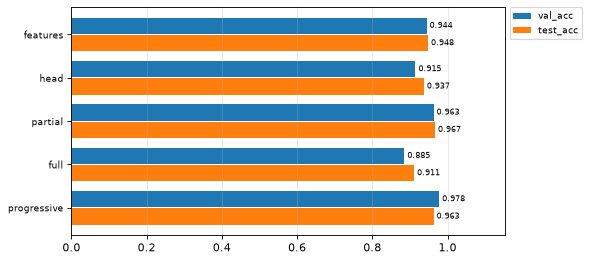

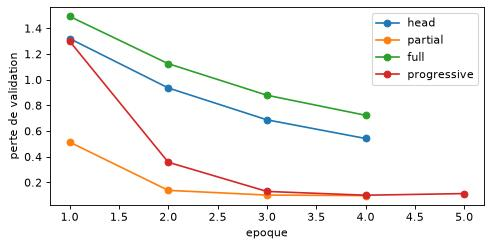

In [13]:
viz.compare_runs(comparison, ["val_acc", "test_acc"])  # barres : exactitude validation et test par strategie
fig, ax = plt.subplots(figsize=(7, 3.2))  # figure de 7 x 3,2 pouces
for strategy, history in histories.items():  # une courbe par strategie entrainee
    # perte de validation par epoque (marker : un point par epoque)
    ax.plot(history["epoch"], history["val_loss"], marker="o", label=strategy)
ax.set_xlabel("epoque")  # titre de l'axe x
ax.set_ylabel("perte de validation")  # titre de l'axe y
ax.legend()  # legende
plt.show()  # affiche la figure

Ce qu'il faut retenir (et que confirment les resultats de la recette sur le jeu complet a
128 px : features 97,8 %, head 95,9 %, partial / full / progressive 100 %) :

- **features** est le premier essai a faire sur un nouveau jeu : quelques secondes, aucun
  hyperparametre delicat, et deja un tres bon niveau ;
- **head** plafonne quand le domaine s'eloigne d'ImageNet : les representations ne bougent pas ;
- des qu'on degele au moins un bloc (**partial**), le modele s'adapte a la texture du metal ;
- **full** demande un taux faible (3e-4) et une montee progressive, sinon il detruit les poids ;
- **progressive** est le plus stable quand les donnees sont bruitees, au prix de plus d'epoques.

En mode QUICK (50 images par classe, 96 px, 4 a 5 epoques) les ecarts sont plus marques et
bruites : a relancer avec `QUICK = False` pour des chiffres a citer.

## 9. Passer en production

Une strategie = quelques lignes de YAML (`recipes/classification/configs/resnet18_<strategie>.yaml`) :

```yaml
model:
  name: resnet18                 # ou efficientnet_b0, convnext_tiny, timm:<nom>, simple_cnn ...
  pretrained: true
  in_channels: 3                 # 1 : premiere convolution a 1 canal (somme des noyaux RGB)
  transfer:
    strategy: partial            # features | head | partial | full | progressive
    unfreeze_last: 1
    backbone_lr_factor: 0.1
    layer_decay: 1.0             # progressive : 0.5
    progressive_every: 2
    freeze_batchnorm: true
```

```
python recipes/classification/scripts/list_models.py      # le catalogue de la toolbox
python recipes/classification/scripts/run.py --config recipes/classification/configs/resnet18_full.yaml
python recipes/classification/scripts/compare.py --outputs outputs/classification
```

Controle : les fonctions de production (`vtb.models.transfer`) gelent les memes parametres et
donnent les memes taux par groupe que les cellules de ce notebook, pour chaque strategie.

In [14]:
from vtb.models.transfer import ModelConfig, TransferConfig, build_classifier  # configs et constructeur de modeles de la toolbox
from vtb.models.transfer import apply_strategy as vtb_apply  # version toolbox, renommee pour ne pas ecraser celle du notebook
from vtb.models.transfer import param_groups as vtb_groups  # idem

checks = []  # lignes du controle
# 4 strategies, avec les reglages qui different des valeurs par defaut
for strategy, settings in {"head": {}, "partial": {"unfreeze_last": 1}, "full": {}, "progressive": {"layer_decay": 0.5}}.items():
    transfer = TransferConfig(strategy=strategy, **settings)  # config de transfert de la toolbox
    # modele de la toolbox (sans poids) et sa description (spec)
    reference, spec = build_classifier(ModelConfig(name="resnet18", pretrained=False, transfer=transfer), len(class_names))
    # gel / degel par la toolbox (2 blocs degeles en progressive)
    vtb_apply(reference, spec, transfer, unfrozen_blocks=2 if strategy == "progressive" else None)
    ours = build_resnet18(len(class_names), pretrained=False)  # notre modele
    apply_strategy(ours, strategy, unfreeze_last=1, unfrozen_blocks=2)  # gel / degel par le notebook
    their_lrs = sorted(g["lr"] for g in vtb_groups(reference, spec, 1e-3, transfer))  # taux par groupe de la toolbox, tries
    our_lrs = sorted(g["lr"] for g in param_groups(ours, 1e-3, 0.1, settings.get("layer_decay", 1.0)))  # taux par groupe du notebook, tries
    checks.append(  # ligne du controle :
        {  # dictionnaire de la ligne
            "strategie": strategy,  # nom de la strategie
            "vtb": count_trainable(reference),  # parametres entraines selon la toolbox
            "notebook": count_trainable(ours),  # selon le notebook (doivent etre egaux)
            "memes taux": np.allclose(their_lrs, our_lrs),  # True attendu
        }
    )
pd.DataFrame(checks)  # derniere ligne : le tableau s'affiche (a verifier a l'oeil : pas d'assert)

,strategie,vtb,notebook,memes taux
0,head,3078,3078,True
1,partial,8396806,8396806,True
2,full,11179590,11179590,True
3,progressive,10496518,10496518,True
